<a href="https://colab.research.google.com/github/LucaSchaerz/2025_Intro_Python/blob/main/live/part-I/1.6-geospatial-vector-data-environmental-exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> Notebook-friendly copy of `part-I/1.6-geospatial-vector-data-environmental-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

In [ ]:
# --- environment setup (generated, not part of the lesson) ---
# Colab and Kaggle do not ship every package this notebook imports.
# This is a no-op in an environment that is already set up.
import importlib.util
import subprocess
import sys

for module, package in {"pooch": "pooch"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# Environmental Exercises

**ℹ️ How to use these exercises**

Attempt each from scratch in the empty code cell. Import geopandas as `gpd`, keep track of the crs at every step, and measure only after reprojecting to a metric crs.

## Exercise 1: Hurricane track analysis

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/nasa-hurricane-florence-2018-09-11.jpg" alt="A satellite view of Hurricane Florence over the Atlantic, a clear eye at the centre of a broad spiral of cloud" width="500">

<em>Hurricane Florence on 11 September 2018, three days before landfall in North Carolina. Image from <a href="https://worldview.earthdata.nasa.gov/">NASA Worldview</a> via <a href="https://commons.wikimedia.org/wiki/File:Florence_2018-09-11_1750Z.jpg">Wikimedia Commons</a>, public domain.</em>


*Can you quickly find out which US states Hurricane Florence passed through using geopandas?*

Apply geopandas to read in the geospatial data, plot, and analyse the track of Hurricane Florence
from 30 August to 18 September 2018. The track is the archived advisory record from the
[National Hurricane Center](https://www.nhc.noaa.gov/); the state boundaries are a
[US Census Bureau](https://www.census.gov/geographies/mapping-files/time-series/geo/carto-boundary-file.html)
cartographic boundary file.

References:

1. [Introduction to GeoPandas](https://geopandas.org/en/stable/getting_started/introduction.html) — geopandas' official website
2. [Geopandas: an introduction](https://autogis-site.readthedocs.io/en/latest/lessons/lesson-2/geopandas-an-introduction.html) — Automating GIS Processes
3. [Use Data for Earth and Environmental Science in Open Source Python](https://www.earthdatascience.org/courses/use-data-open-source-python/)
4. [The Shapely User Manual](https://shapely.readthedocs.io/en/stable/manual.html)
5. [Geospatial Analysis with Python and R](https://kodu.ut.ee/~kmoch/geopython2020/index.html)

In [1]:
# Pre-supplied: download and cache the two real data files.
import pooch

states_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/gz_2010_us_040_00_5m.json",
    known_hash="sha256:7a8c022e063a34a83f35984cde6c81992ece5983f8cc4459ed02e40687739573",
    fname="us_states.geojson",
    path=pooch.os_cache("mlees"),
)
track_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/florence.csv",
    known_hash="sha256:385691583ee41682a1c905e042c56ea362609fb04645934bdda7911c55c8b63f",
    fname="florence.csv",
    path=pooch.os_cache("mlees"),
)

**ℹ️ Where the tools come from**

Every tool the questions need has been demonstrated already. `read_file`, `.plot()`, `GeoDataFrame`,
`gpd.points_from_xy`, `.crs`, `geom_type`, the MultiPolygon type, `.isin()`, `overlay`, `.centroid`,
`to_crs`, `buffer` and the spatial predicates are from this subchapter's lecture; `.head()` and
boolean filtering are from 1.5, and `unique` from 1.5's earthquake exercise. `ax.annotate`, which Q8
uses to label each state, is from 1.4.

**Q1) Import geopandas and pandas.**

Import geopandas as `gpd`, pandas as `pd`, and matplotlib's pyplot as `plt`.

In [7]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

# Import geopandas (as gpd), pandas, and matplotlib

**Q2) Read the state boundary file with geopandas' `read_file` function.**

The file is cached at `states_path`. Call the result `country`.

In [16]:
# Read the data with the geopandas function
country = gpd.read_file(states_path)

**Q3) Have a look at the data. What type of geometries does it contain?**

Print the first few rows, and answer the geometry question in a comment.

In [17]:
# Print out the first few lines of the data
print(country.geometry.head(3))

# 0    MULTIPOLYGON (((-88.12466 30.28364, -88.08681 ...
# 1    MULTIPOLYGON (((-166.10574 53.98861, -166.0752...
# 2    POLYGON ((-112.53859 37.00067, -112.53454 37.0...
# Name: geometry, dtype: geometry

0    MULTIPOLYGON (((-88.12466 30.28364, -88.08681 ...
1    MULTIPOLYGON (((-166.10574 53.98861, -166.0752...
2    POLYGON ((-112.53859 37.00067, -112.53454 37.0...
Name: geometry, dtype: geometry


**Q4) Have a look at the data on a map using geopandas' `.plot()` method.**

Exclude Alaska and Hawaii using the `NAME` attribute and pandas' `.isin()` method. Specify the
figsize to be 30 x 20.

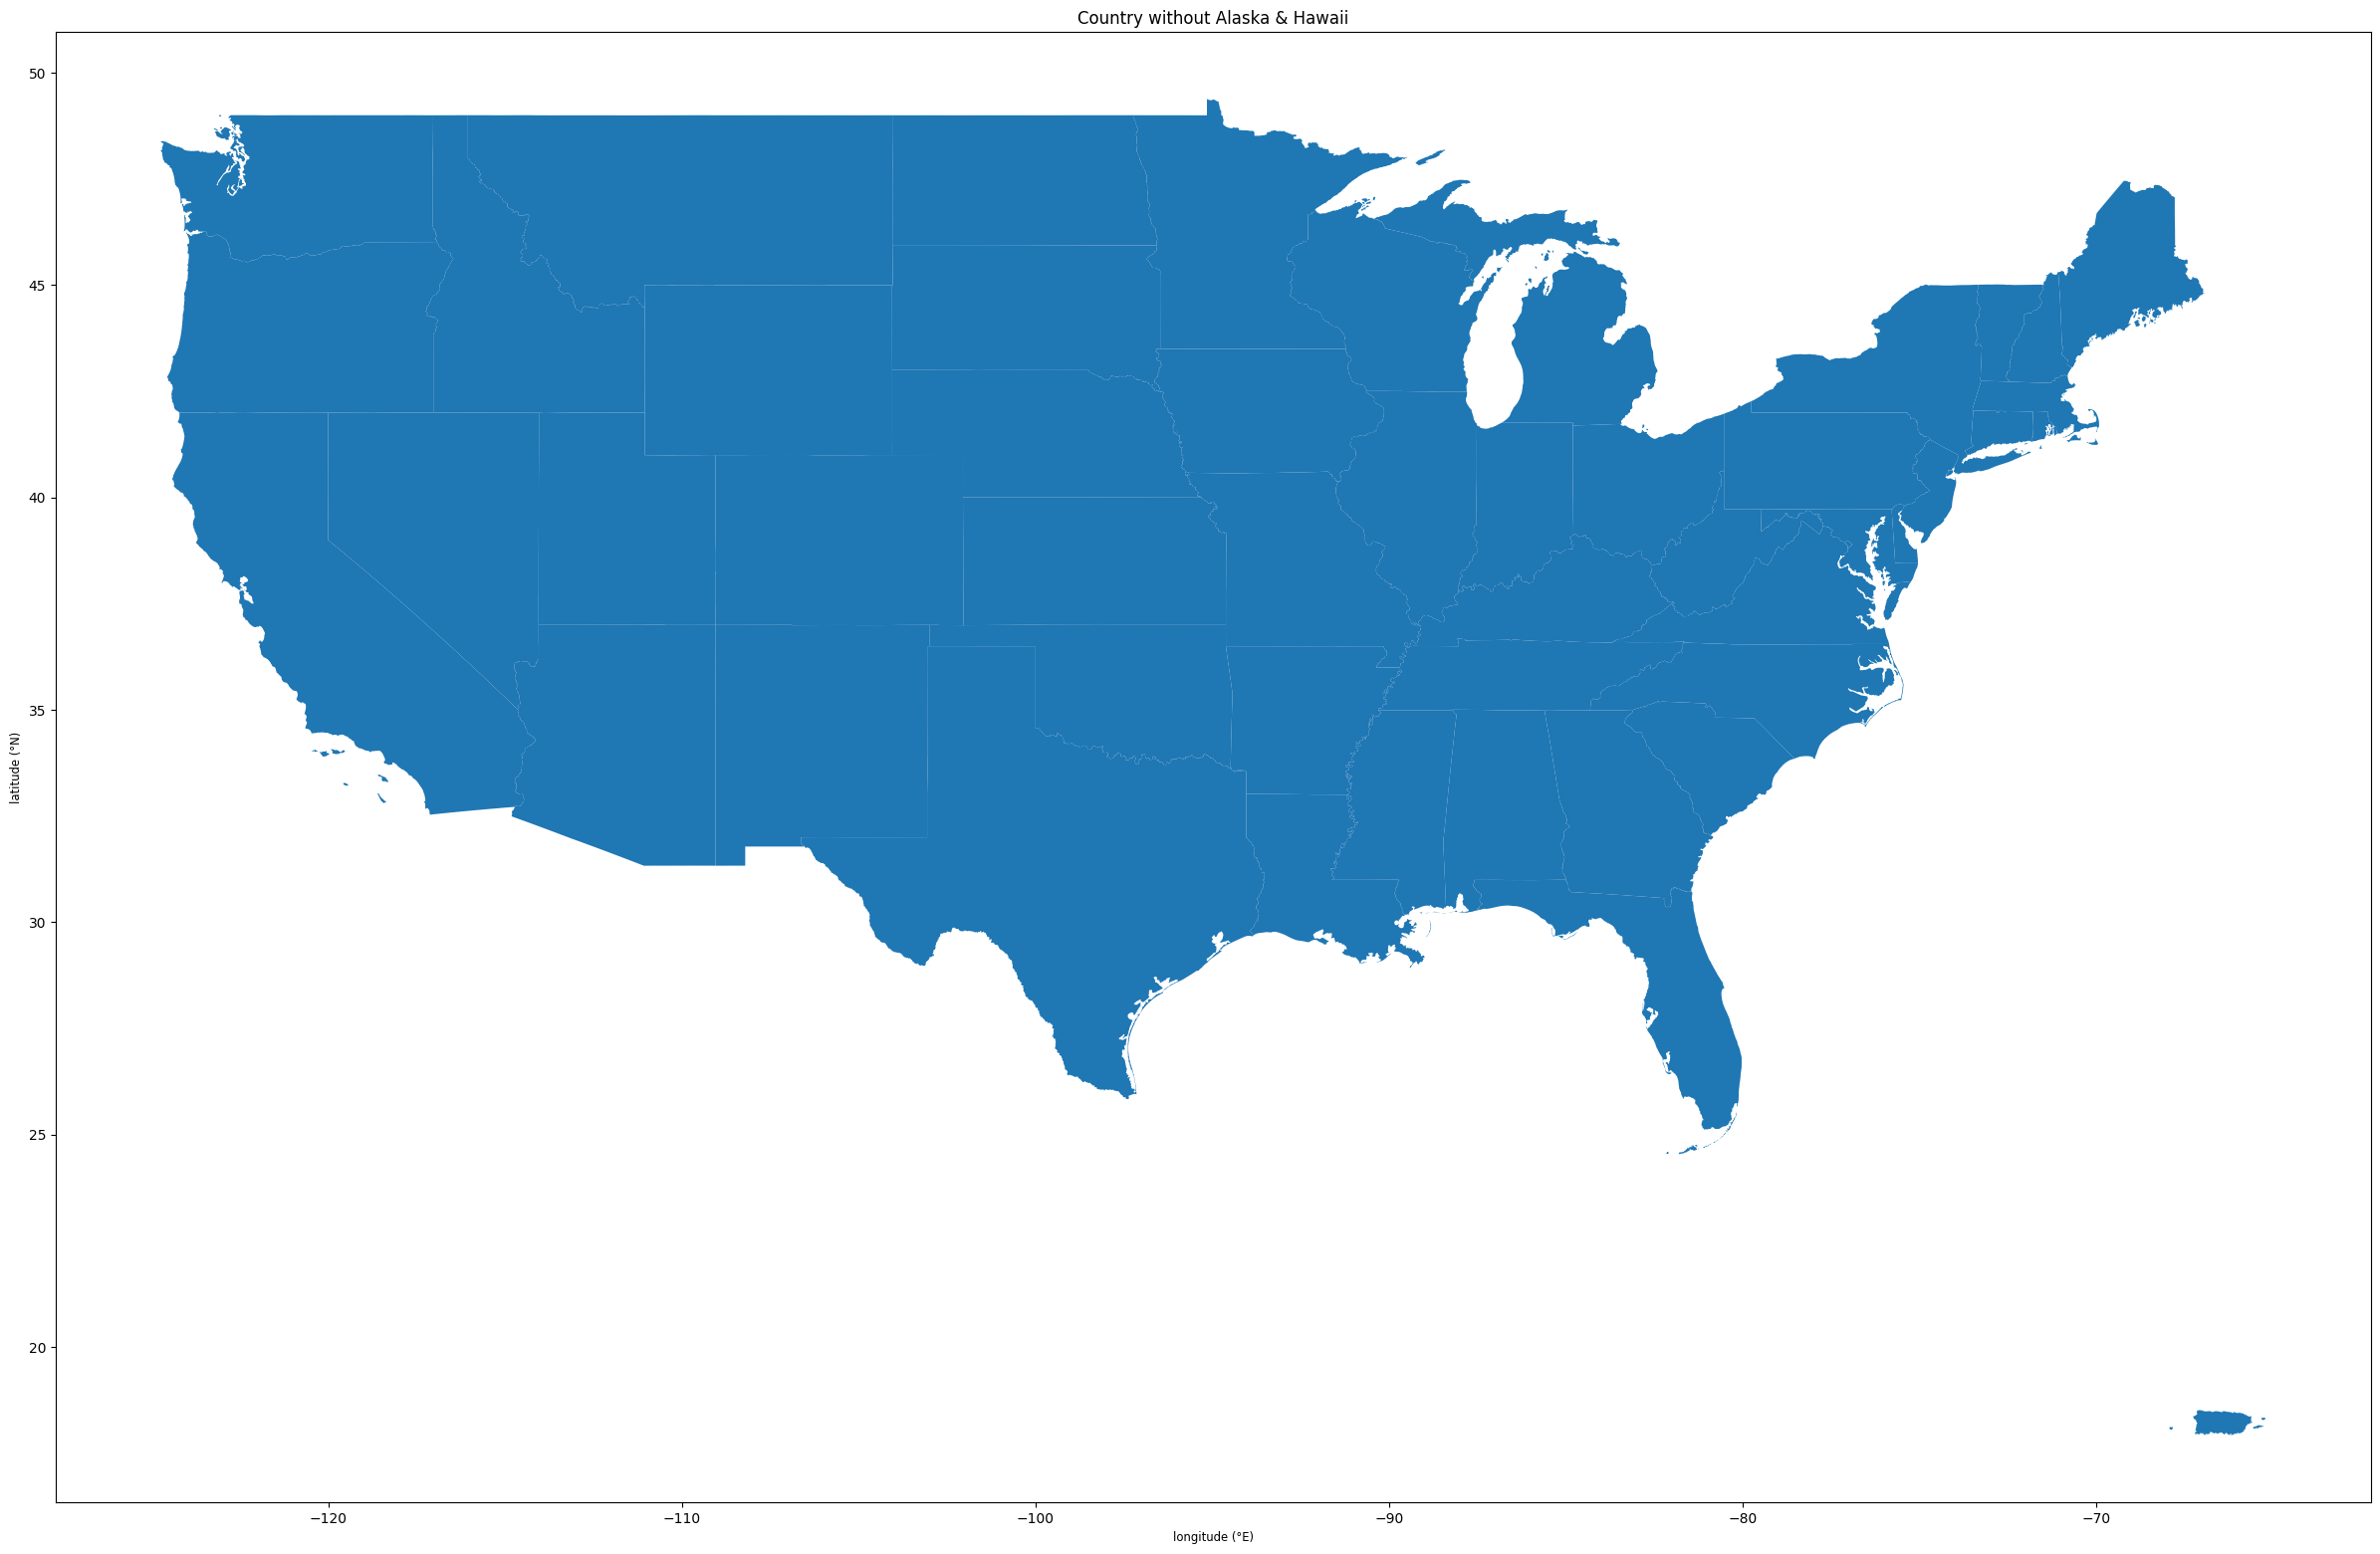

In [21]:
# Plot the US states (Alaska and Hawaii excluded)
flagged = country[~country["NAME"].isin(["Alaska", "Hawaii"])]

fig, ax = plt.subplots(figsize=(30, 20))
flagged.plot(ax=ax)
ax.set_xlabel("longitude (°E)")
ax.set_ylabel("latitude (°N)")
ax.set_title("Country without Alaska & Hawaii")
plt.show()

In [22]:
# Pre-supplied: read in the hurricane Florence data, drop the advisory bookkeeping columns,
# fix the longitude sign, and have a look at the dataframe.
# The Long column holds a positive "degrees west" magnitude, not a signed longitude -- a common
# quirk of NHC advisory data.
florence = pd.read_csv(track_path)
florence = florence.drop(["AdvisoryNumber", "Forecaster", "Received"], axis=1)
florence["Long"] = 0 - florence["Long"]
florence.head(3)

,Date,Lat,Long,Wind,Pres,Movement,Type,Name
0,08/30/2018 11:00,12.9,-18.4,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six
1,08/30/2018 14:00,12.9,-19.0,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six
2,08/30/2018 17:00,12.9,-19.4,30,1007,W at 9 MPH (280 deg),Potential Tropical Cyclone,Six


**Q5) Create a GeoDataFrame from the `florence` DataFrame.**

Build the geometry column from the `Long` and `Lat` columns with
[`gpd.points_from_xy`](https://geopandas.org/en/stable/docs/reference/api/geopandas.points_from_xy.html),
and call the result `gdf_florence`. Then look at its first few rows.

In [27]:
# Create a geodataframe from the hurricane florence dataframe
gdf_florence = gpd.GeoDataFrame(
    florence,
    geometry=gpd.points_from_xy(florence["Long"], florence["Lat"]),
    crs="EPSG:4326",   # WGS84 longitude/latitude in degrees
)

gdf_florence.head(3)

,Date,Lat,Long,Wind,Pres,Movement,Type,Name,geometry
0,08/30/2018 11:00,12.9,-18.4,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six,POINT (-18.4 12.9)
1,08/30/2018 14:00,12.9,-19.0,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six,POINT (-19 12.9)
2,08/30/2018 17:00,12.9,-19.4,30,1007,W at 9 MPH (280 deg),Potential Tropical Cyclone,Six,POINT (-19.4 12.9)


**Q6) Plot the US states map (without Alaska and Hawaii) and hurricane Florence together.**

Draw the states as a base map, then plot the hurricane positions on top in a colour that stands
out.

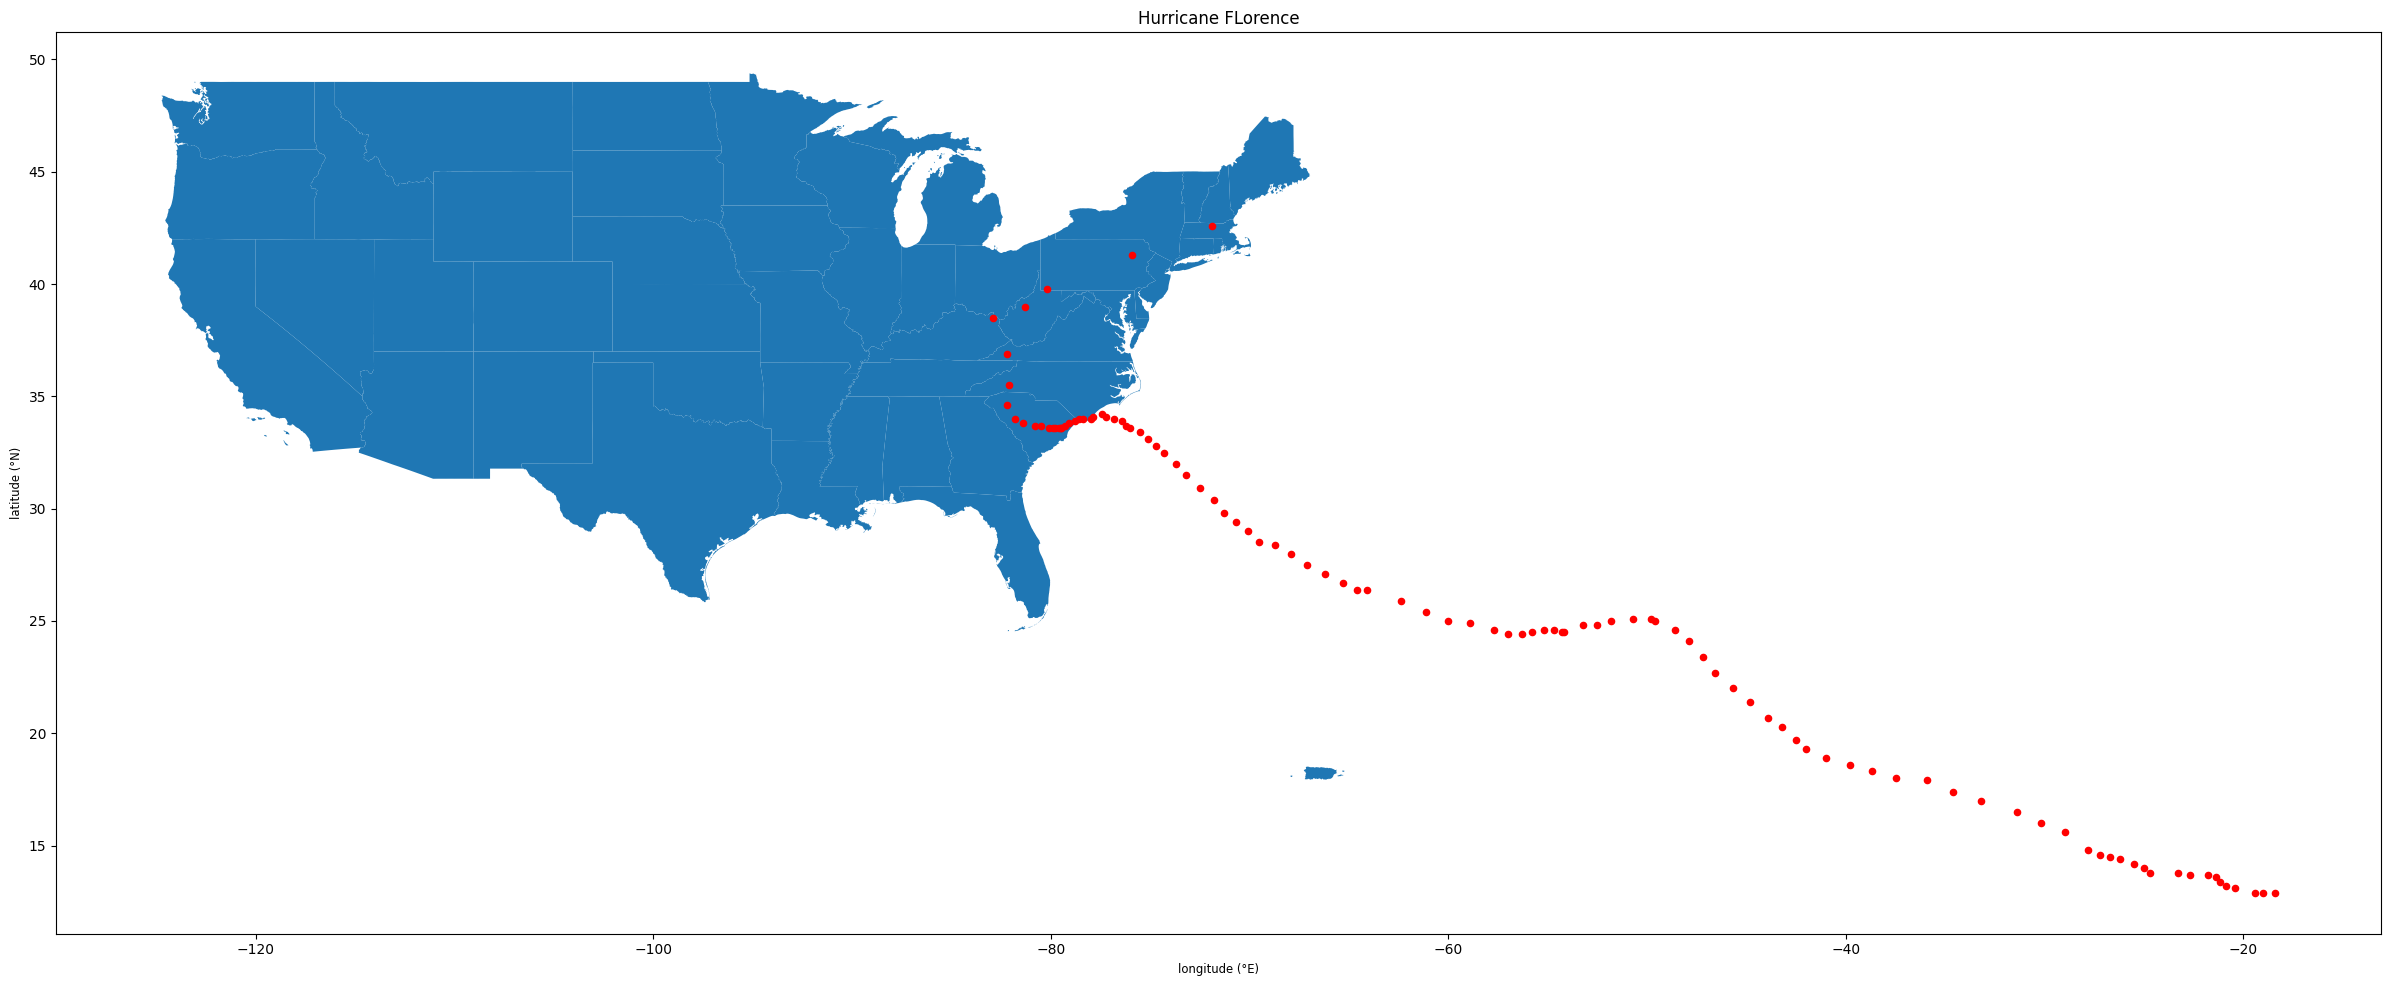

In [30]:
# Plot to see the hurricane overlay the US map, with the hurricane position on top
fig, ax = plt.subplots(figsize=(30, 20))
flagged.plot(ax=ax)
gdf_florence.plot(ax=ax, color="red", markersize=20)

ax.set_xlabel("longitude (°E)")
ax.set_ylabel("latitude (°N)")
ax.set_title("Hurricane FLorence")


plt.show()

**Q7) What is the coordinate reference system of the data?**

Check it for both layers, and say in a comment whether they match — two layers only line up on
one pair of axes if they share a crs.

In [32]:
# Check the coordinate reference system of the data
print(flagged.crs)
print(gdf_florence.crs)

#le systeme de coordonnées est le même

EPSG:4326
EPSG:4326


**Q8) Which states did the hurricane pass through?**

```{hint}
One approach is to plot the trajectory over the US map, annotate each state with its name, and
read the answer off the figure. Other approaches are more than welcome — `overlay` with
`how="intersection"` will give you the track points that fall inside a state polygon, and the
`NAME` column of the result then answers the question directly.
```

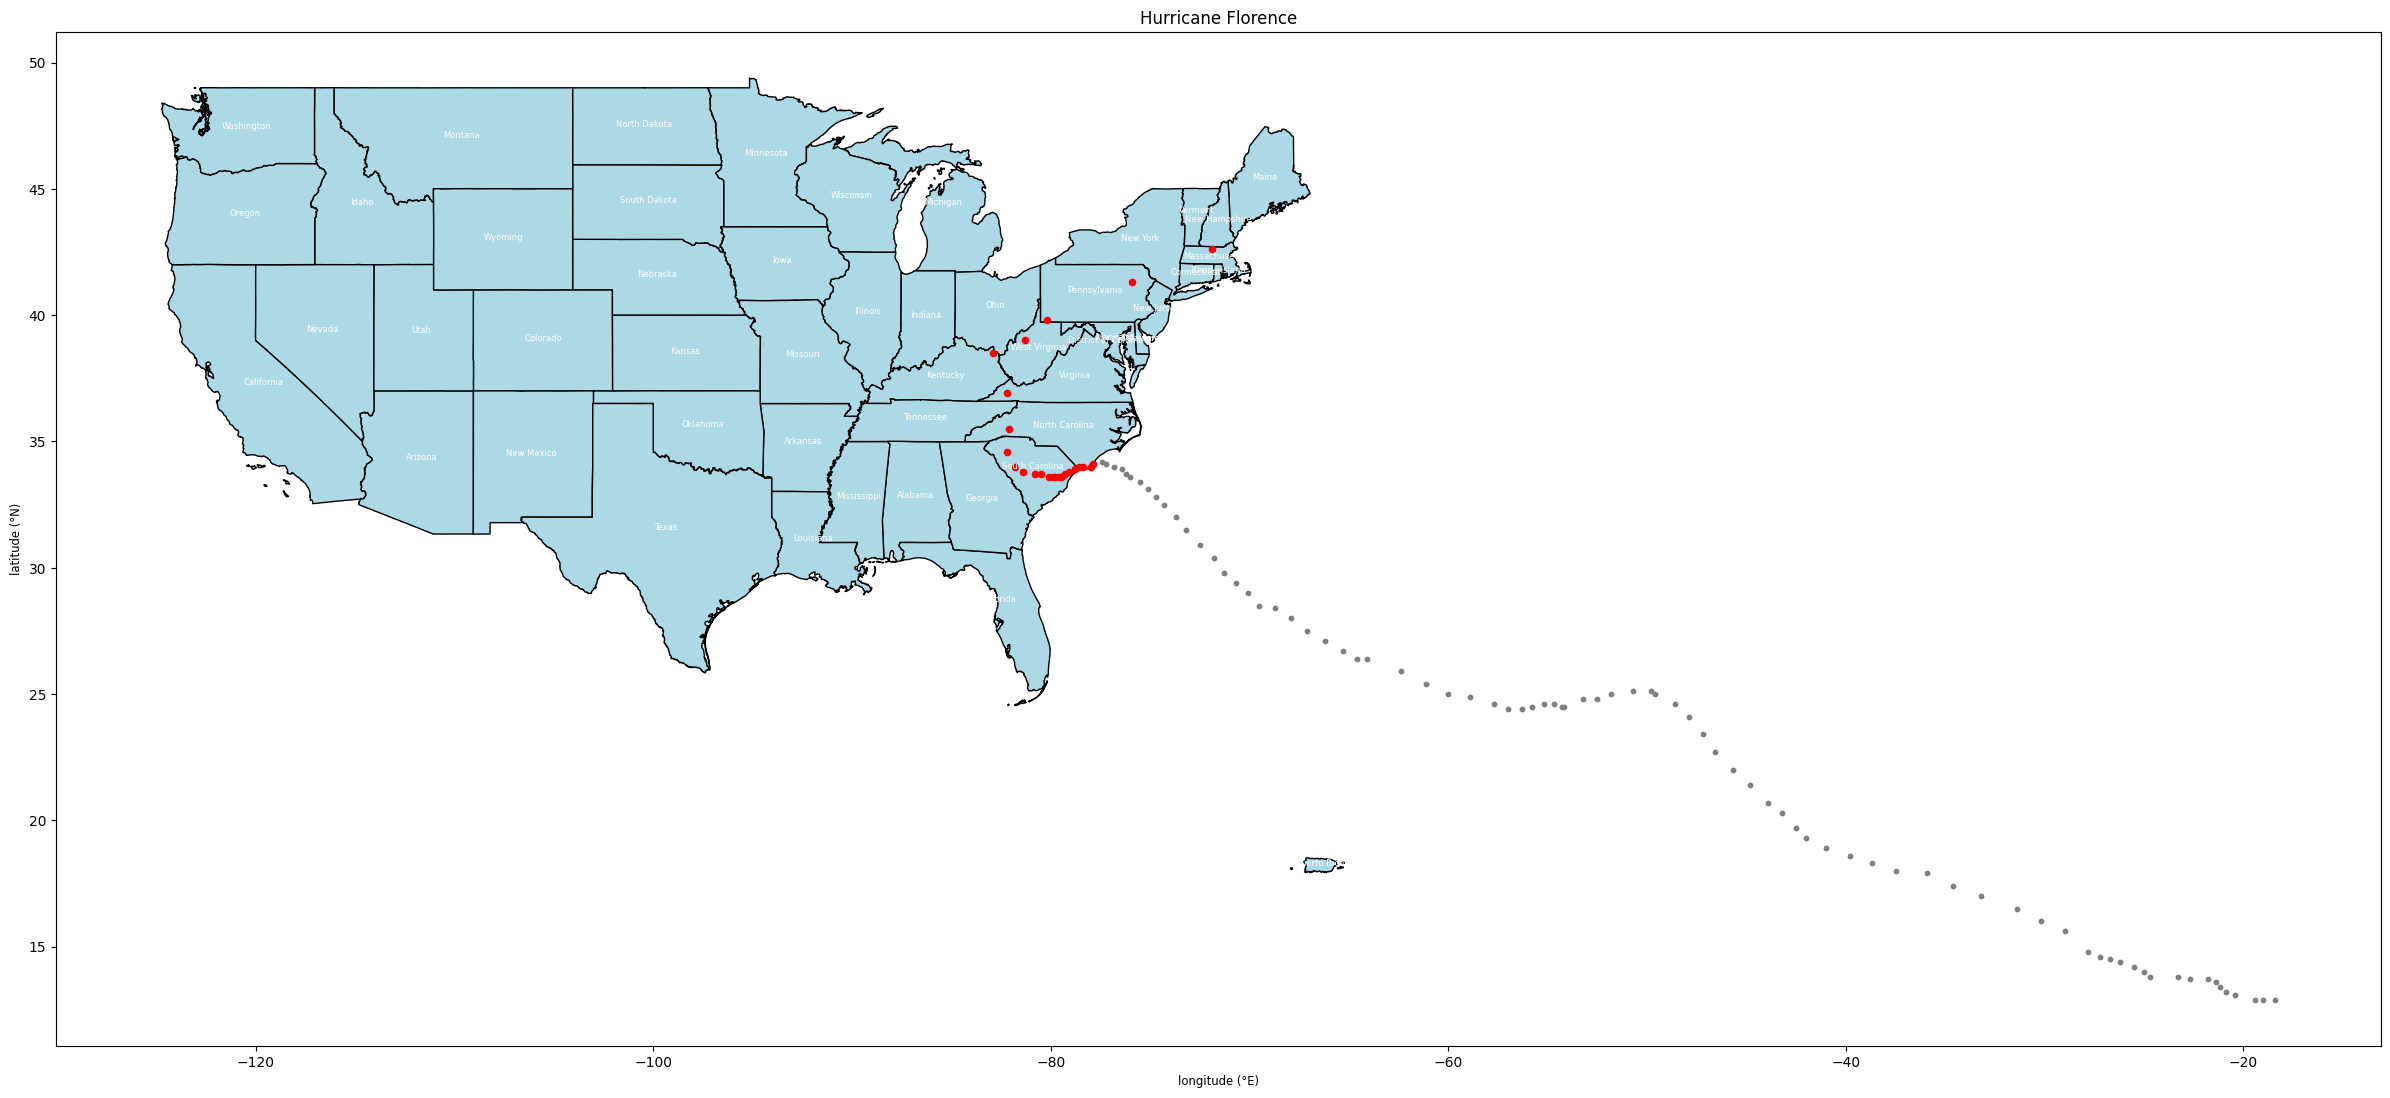

In [57]:

florence_inside = gpd.overlay(gdf_florence, flagged, how="intersection")

fig, ax = plt.subplots(figsize=(30, 20))

flagged.plot(ax=ax, color="lightblue", edgecolor="black")

for idx, row in flagged.iterrows():
    x = row.geometry.centroid.x
    y = row.geometry.centroid.y
    ax.annotate(text=row["NAME"], xy=(x, y), ha="center", fontsize=6, color="white")

# 5. Trajectoire complète (gris) puis partie à l'intérieur des États-Unis (rouge)
gdf_florence.plot(ax=ax, color="grey", markersize=10)
florence_inside.plot(ax=ax, color="red", markersize=20)

ax.set_xlabel("longitude (°E)")
ax.set_ylabel("latitude (°N)")
ax.set_title("Hurricane Florence")
plt.show()
# Plot the US states without Alaska and Hawaii, then
# annotate the US states with their names, then
# select the hurricane trajectory points inside the US boundary with the overlay operation, then
# plot the hurricane trajectory inside the US boundary